
# Description

This notebook performs sentiment analysis on financial news headlines using the Natural Language Toolkit (NLTK).

The project uses the Financial PhraseBank dataset available on Kaggle, which contains financial news sentences labeled as positive, negative, or neutral.

The analysis includes:
- Loading and exploring the financial news dataset.
- Preprocessing text using NLTK tokenization, stopword removal, and lemmatization.
- Creating a majority-class baseline.
- Applying VADER sentiment analysis.
- Training a Naive Bayes classifier using bag-of-words features.
- Evaluating model performance using accuracy, macro F1-score, and confusion matrices.
- Visualizing word frequencies and informative features.

References:
- NLTK Documentation: https://www.nltk.org/
- Financial News Dataset: https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news


## Imports

In [4]:
%load_ext autoreload
%autoreload 2

# System libraries.
import logging
from pathlib import Path

# Data analysis and visualization.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# NLTK libraries.
import nltk
from nltk import FreqDist, NaiveBayesClassifier, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer

# Model evaluation.
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

# Dataset downloading.
import kagglehub

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
# Download the Financial PhraseBank dataset from Kaggle.
dataset_path = kagglehub.dataset_download(
    "ankurzing/sentiment-analysis-for-financial-news"
)

# Display the dataset location and available files.
print("Dataset downloaded to:", dataset_path)

print("\nAvailable files:")
for file_path in Path(dataset_path).rglob("*"):
    if file_path.is_file():
        print(file_path.relative_to(dataset_path))

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 903k/903k [00:00<00:00, 23.8MB/s]

Extracting files...
Dataset downloaded to: /Users/dharshan/.cache/kagglehub/datasets/ankurzing/sentiment-analysis-for-financial-news/versions/5

Available files:
all-data.csv
FinancialPhraseBank/Sentences_66Agree.txt
FinancialPhraseBank/Sentences_AllAgree.txt
FinancialPhraseBank/Sentences_50Agree.txt
FinancialPhraseBank/README.txt
FinancialPhraseBank/License.txt
FinancialPhraseBank/Sentences_75Agree.txt


In [6]:
# Load the financial news dataset.
csv_path = Path(dataset_path) / "all-data.csv"

df = pd.read_csv(
    csv_path,
    encoding="latin-1",
    header=None,
    names=["sentiment", "headline"]
)

# Display the dataset size and first few rows.
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

Dataset shape: (4846, 2)

First five rows:


,sentiment,headline
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...


In [7]:
# Check the dataset for missing values and duplicates.
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate headlines:")
print(df["headline"].duplicated().sum())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nSentiment percentages:")
print(df["sentiment"].value_counts(normalize=True).mul(100).round(2))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4846 entries, 0 to 4845
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sentiment  4846 non-null   object
 1   headline   4846 non-null   object
dtypes: object(2)
memory usage: 75.8+ KB

Missing values:
sentiment    0
headline     0
dtype: int64

Duplicate headlines:
8

Sentiment distribution:
sentiment
neutral     2879
positive    1363
negative     604
Name: count, dtype: int64

Sentiment percentages:
sentiment
neutral     59.41
positive    28.13
negative    12.46
Name: proportion, dtype: float64


In [9]:
# Display repeated headlines and their sentiment labels.
duplicate_rows = df[
    df.duplicated(subset=["headline"], keep=False)
].sort_values("headline")

print("Rows containing duplicate headlines:", len(duplicate_rows))

display(duplicate_rows)

# Check whether any repeated headlines have different labels.
conflicting_labels = (
    df.groupby("headline")["sentiment"]
    .nunique()
)

print(
    "\nHeadlines with conflicting sentiment labels:",
    (conflicting_labels > 1).sum()
)

Rows containing duplicate headlines: 16


,sentiment,headline
2395,neutral,Ahlstrom 's share is quoted on the NASDAQ OMX ...
2396,neutral,Ahlstrom 's share is quoted on the NASDAQ OMX ...
3093,neutral,Proha Plc ( Euronext :7327 ) announced today (...
3094,neutral,Proha Plc ( Euronext :7327 ) announced today (...
2566,neutral,SSH Communications Security Corporation is hea...
2567,neutral,SSH Communications Security Corporation is hea...
78,neutral,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sel...
79,positive,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sel...
788,positive,The Group 's business is balanced by its broad...
789,neutral,The Group 's business is balanced by its broad...



Headlines with conflicting sentiment labels: 2


In [10]:
# Identify headlines with conflicting sentiment labels.
label_counts = df.groupby("headline")["sentiment"].nunique()
conflicting_headlines = label_counts[label_counts > 1].index

# Remove headlines that have conflicting labels.
df_clean = df[
    ~df["headline"].isin(conflicting_headlines)
].copy()

# Keep one copy of each remaining headline.
df_clean = df_clean.drop_duplicates(subset=["headline"])

# Reset the row numbers.
df_clean = df_clean.reset_index(drop=True)

# Check the cleaned dataset.
print("Original dataset:", len(df))
print("Cleaned dataset:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print("\nRemaining duplicate headlines:")
print(df_clean["headline"].duplicated().sum())

print("\nCleaned sentiment distribution:")
print(df_clean["sentiment"].value_counts())

Original dataset: 4846
Cleaned dataset: 4836
Rows removed: 10

Remaining duplicate headlines:
0

Cleaned sentiment distribution:
sentiment
neutral     2871
positive    1361
negative     604
Name: count, dtype: int64


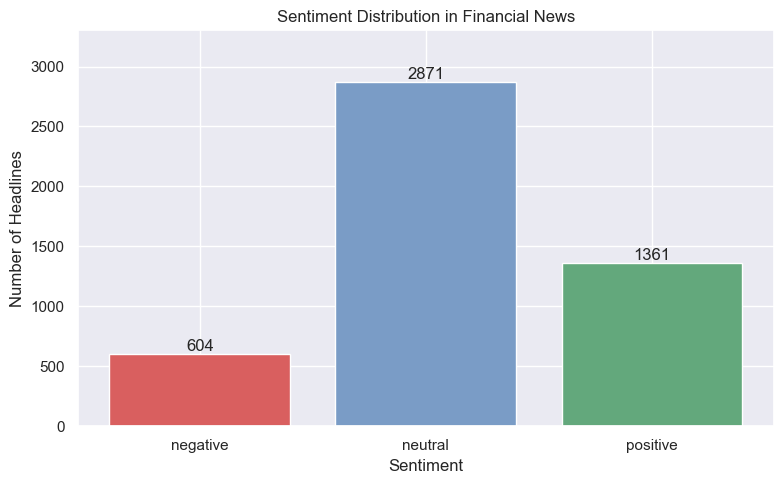

In [11]:
# Count the headlines in each sentiment class.
sentiment_order = ["negative", "neutral", "positive"]
sentiment_counts = (
    df_clean["sentiment"]
    .value_counts()
    .reindex(sentiment_order)
)

# Plot the sentiment distribution.
plt.figure(figsize=(8, 5))

bars = plt.bar(
    sentiment_counts.index,
    sentiment_counts.values,
    color=["#d95f5f", "#7a9cc6", "#63a87c"]
)

# Display the count above each bar.
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 25,
        str(int(bar.get_height())),
        ha="center"
    )

plt.title("Sentiment Distribution in Financial News")
plt.xlabel("Sentiment")
plt.ylabel("Number of Headlines")
plt.ylim(0, sentiment_counts.max() * 1.15)
plt.tight_layout()
plt.show()

### Observation

The dataset contains more neutral headlines than positive or negative headlines. Neutral accounts for approximately 59% of the data, while negative headlines account for only about 12%.

This imbalance is important because a model could achieve relatively high accuracy by predicting the majority class. To evaluate the models fairly, I will use a stratified train-test split and compare accuracy with macro F1-score.

## Train-Test Split

The cleaned dataset is divided into training and testing sets using an 80/20 split. Stratified sampling is used to maintain the sentiment distribution in both sets. A fixed random seed is used to make the results reproducible.

In [12]:
# Separate the headlines and sentiment labels.
X = df_clean["headline"]
y = df_clean["sentiment"]

# Split the data while preserving the sentiment distribution.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the size of each set.
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Compare the sentiment distribution in both sets.
print("\nTraining sentiment distribution (%):")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting sentiment distribution (%):")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training samples: 3868
Testing samples: 968

Training sentiment distribution (%):
sentiment
neutral     59.36
positive    28.15
negative    12.49
Name: proportion, dtype: float64

Testing sentiment distribution (%):
sentiment
neutral     59.4
positive    28.1
negative    12.5
Name: proportion, dtype: float64


## Majority-Class Baseline

A majority-class baseline predicts the most frequent sentiment label in the training set for every test headline.

This provides a simple benchmark for evaluating VADER and Naive Bayes. Since the dataset is imbalanced, both accuracy and macro F1-score are used to compare model performance.

In [13]:
# Find the most common sentiment in the training data.
majority_class = y_train.mode()[0]

# Predict the majority class for every test headline.
baseline_predictions = [majority_class] * len(y_test)

# Evaluate the baseline model.
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_f1 = f1_score(
    y_test,
    baseline_predictions,
    average="macro",
    zero_division=0
)

print("Majority class:", majority_class)
print("Baseline accuracy:", round(baseline_accuracy, 4))
print("Baseline macro F1-score:", round(baseline_f1, 4))

Majority class: neutral
Baseline accuracy: 0.594
Baseline macro F1-score: 0.2484


## VADER Sentiment Analysis

VADER is a lexicon-based sentiment analysis method available in NLTK. It assigns sentiment scores to text without requiring model training.

In this experiment, VADER is applied to the test headlines and its predictions are compared with the actual sentiment labels.

In [14]:
# Download the VADER lexicon if it is not already available.
nltk.download("vader_lexicon", quiet=True)

# Initialize the VADER sentiment analyzer.
vader = SentimentIntensityAnalyzer()

# Convert VADER compound scores into sentiment labels.
def predict_vader_sentiment(text):
    score = vader.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"

# Predict sentiment for the test headlines.
vader_predictions = [
    predict_vader_sentiment(headline)
    for headline in X_test
]

# Evaluate VADER predictions.
vader_accuracy = accuracy_score(y_test, vader_predictions)
vader_f1 = f1_score(
    y_test,
    vader_predictions,
    average="macro",
    zero_division=0
)

print("VADER accuracy:", round(vader_accuracy, 4))
print("VADER macro F1-score:", round(vader_f1, 4))

VADER accuracy: 0.5444
VADER macro F1-score: 0.4947


### VADER Model Evaluation

The VADER model is evaluated using a classification report and confusion matrix. These results help identify how well the model predicts each sentiment class and where misclassifications occur.

VADER Classification Report:

              precision    recall  f1-score   support

    negative       0.44      0.31      0.37       121
     neutral       0.74      0.52      0.61       575
    positive       0.40      0.70      0.51       272

    accuracy                           0.54       968
   macro avg       0.53      0.51      0.49       968
weighted avg       0.61      0.54      0.55       968



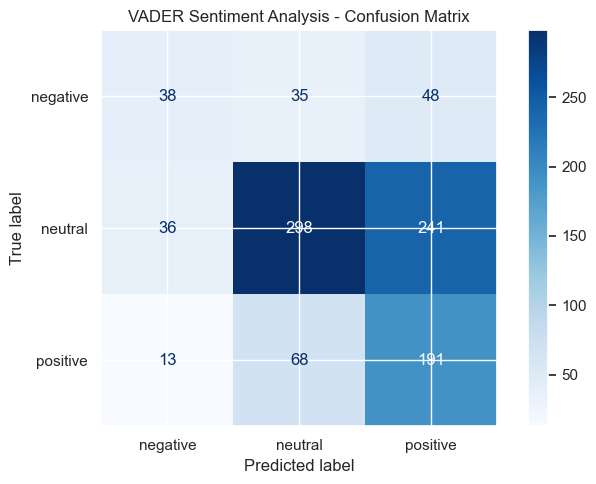

In [15]:
# Define the sentiment classes in a consistent order.
sentiment_labels = ["negative", "neutral", "positive"]

# Display precision, recall, and F1-score for each class.
print("VADER Classification Report:\n")

print(
    classification_report(
        y_test,
        vader_predictions,
        labels=sentiment_labels,
        zero_division=0
    )
)

# Calculate and display the confusion matrix.
cm = confusion_matrix(
    y_test,
    vader_predictions,
    labels=sentiment_labels
)

fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sentiment_labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("VADER Sentiment Analysis - Confusion Matrix")
plt.tight_layout()
plt.show()

### VADER Results Discussion

VADER achieved an accuracy of 54.44% and a macro F1-score of 0.4947. Its accuracy was lower than the majority-class baseline of 59.40%, but its macro F1-score was higher.

The confusion matrix shows that VADER performed better at identifying positive headlines than negative headlines. It correctly identified only 38 out of 121 negative headlines and incorrectly classified 241 neutral headlines as positive.

These results suggest that VADER's general-purpose sentiment rules may not fully capture the meaning of financial news. A supervised classifier trained on financial headlines may perform better.

## Naive Bayes Sentiment Classification

Unlike VADER, Naive Bayes is a supervised machine learning classifier that learns from labeled financial news headlines.

The text is preprocessed using NLTK tokenization, stopword removal, and lemmatization. The processed words are then converted into bag-of-words features for classification.

The model will be trained using the training dataset and evaluated on the separate test dataset.

In [16]:
# Download the NLTK resources needed for preprocessing.
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# Initialize the preprocessing tools.
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# Keep negation words because they can change sentiment.
stop_words = stop_words - {"no", "not", "nor"}

def preprocess_text(text):
    # Convert text to lowercase and tokenize it.
    tokens = word_tokenize(text.lower())

    # Remove punctuation and stopwords, then lemmatize.
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    return cleaned_tokens

# Test preprocessing on one financial headline.
sample_headline = "The company reported strong profits and rising shares."

print("Original headline:", sample_headline)
print("Processed tokens:", preprocess_text(sample_headline))

Original headline: The company reported strong profits and rising shares.
Processed tokens: ['company', 'reported', 'strong', 'profit', 'rising', 'share']


In [17]:
# Convert each headline into bag-of-words features.
def extract_features(text):
    tokens = preprocess_text(text)
    return {word: True for word in tokens}

# Prepare the training data with sentiment labels.
train_features = [
    (extract_features(headline), label)
    for headline, label in zip(X_train, y_train)
]

# Train the Naive Bayes classifier.
nb_classifier = NaiveBayesClassifier.train(train_features)

# Check the number of training samples.
print("Training samples:", len(train_features))
print("Naive Bayes model trained successfully.")

Training samples: 3868
Naive Bayes model trained successfully.


In [18]:
# Prepare the test headlines using the same feature extraction.
test_features = [
    extract_features(headline)
    for headline in X_test
]

# Predict sentiment using the trained Naive Bayes classifier.
nb_predictions = [
    nb_classifier.classify(features)
    for features in test_features
]

# Calculate accuracy and macro F1-score.
nb_accuracy = accuracy_score(y_test, nb_predictions)

nb_f1 = f1_score(
    y_test,
    nb_predictions,
    average="macro",
    zero_division=0
)

# Display the evaluation results.
print("Naive Bayes accuracy:", round(nb_accuracy, 4))
print("Naive Bayes macro F1-score:", round(nb_f1, 4))

Naive Bayes accuracy: 0.6508
Naive Bayes macro F1-score: 0.6146


Naive Bayes Classification Report:

              precision    recall  f1-score   support

    negative       0.41      0.79      0.54       121
     neutral       0.85      0.65      0.73       575
    positive       0.55      0.60      0.57       272

    accuracy                           0.65       968
   macro avg       0.60      0.68      0.61       968
weighted avg       0.71      0.65      0.66       968



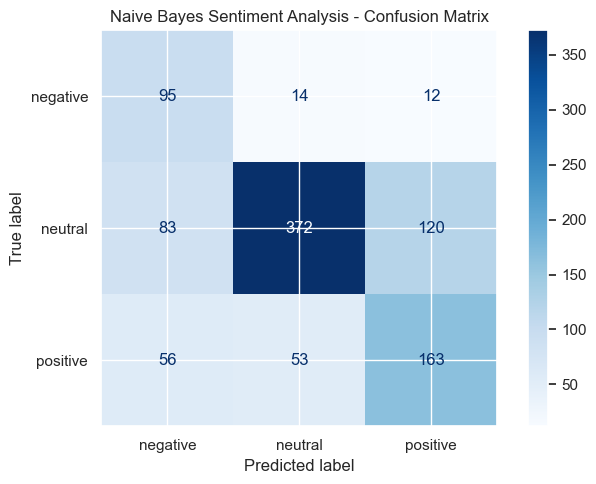

In [19]:
# Display classification metrics for each sentiment class.
print("Naive Bayes Classification Report:\n")

print(
    classification_report(
        y_test,
        nb_predictions,
        labels=sentiment_labels,
        zero_division=0
    )
)

# Calculate the Naive Bayes confusion matrix.
nb_cm = confusion_matrix(
    y_test,
    nb_predictions,
    labels=sentiment_labels
)

# Visualize the confusion matrix.
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=nb_cm,
    display_labels=sentiment_labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Naive Bayes Sentiment Analysis - Confusion Matrix")
plt.tight_layout()
plt.show()

### Naive Bayes Feature Analysis

The most informative features are examined to understand which words help the classifier distinguish between financial news sentiment classes.

In [20]:
# Display the most informative features learned from training data.
print("Top 20 most informative features:\n")
nb_classifier.show_most_informative_features(20)

Top 20 most informative features:

Most Informative Features
               decreased = True           negati : positi =     75.8 : 1.0
                    rose = True           positi : neutra =     47.3 : 1.0
                    grew = True           positi : neutra =     38.6 : 1.0
           corresponding = True           negati : neutra =     34.1 : 1.0
                 dropped = True           negati : neutra =     33.2 : 1.0
                    fell = True           negati : positi =     30.2 : 1.0
             temporarily = True           negati : neutra =     30.1 : 1.0
                    loss = True           negati : neutra =     28.2 : 1.0
                compared = True           negati : neutra =     27.7 : 1.0
              continuing = True           negati : neutra =     26.9 : 1.0
               increased = True           positi : neutra =     23.9 : 1.0
                  layoff = True           negati : neutra =     20.6 : 1.0
                positive = True        

### Naive Bayes Feature Discussion

The most informative features show that the classifier has learned several useful patterns from financial news. Words such as "rose", "grew", and "increased" are associated with positive sentiment, while "decreased", "fell", and "loss" are associated with negative sentiment.

Some features, including "pm" and "item", do not have an obvious relationship with financial sentiment. This suggests that the classifier may also learn patterns that are specific to the training dataset.

Overall, the results show that Naive Bayes can identify meaningful sentiment-related words, although individual word features may not always capture the full context of a headline.

In [21]:
# Compare the actual labels with Naive Bayes predictions.
error_analysis = pd.DataFrame({
    "headline": X_test.values,
    "actual_sentiment": y_test.values,
    "predicted_sentiment": nb_predictions
})

# Select the incorrectly classified headlines.
misclassified = error_analysis[
    error_analysis["actual_sentiment"]
    != error_analysis["predicted_sentiment"]
]

print("Total test headlines:", len(error_analysis))
print("Misclassified headlines:", len(misclassified))

print("\nExamples of incorrect predictions:")
display(misclassified.head(10))

Total test headlines: 968
Misclassified headlines: 338

Examples of incorrect predictions:


,headline,actual_sentiment,predicted_sentiment
1,Martela said plans to expand its recycled furn...,positive,neutral
3,Net profit in the same period in 2006 was ( x...,neutral,negative
8,It projected revenue of $ 2.2 billion to $ 2.3...,positive,negative
10,All are welcome .,neutral,positive
16,Sales fell abroad but increased in Finland .,neutral,negative
19,This new representation extends Comptel 's glo...,positive,neutral
21,"In the Asia-Pacific region , Visa Wave is avai...",positive,neutral
22,Maggie Ramsey 's wait - and those of thousands...,neutral,negative
26,EBIT margin was up from 1.4 % to 5.1 % .,positive,negative
28,The company had net sales of EUR 10.8 million ...,neutral,negative


### Naive Bayes Error Analysis

The Naive Bayes classifier incorrectly classified 338 out of 968 test headlines.

Some errors involve headlines containing both positive and negative information. For example, the headline about sales falling abroad but increasing in Finland was labeled neutral, while the model predicted negative.

Other errors involve financial measurements, such as an increase in EBIT margin. The current preprocessing removes numbers, which may cause the model to lose useful information.

These examples show that word-based features can identify sentiment-related terms but may struggle with context, numerical changes, and mixed sentiment.

## TF-IDF and Logistic Regression

A TF-IDF representation is used to convert financial headlines into numerical features. Logistic Regression is trained as an additional supervised classifier and compared with Naive Bayes.

Model selection will use cross-validation on the training data to avoid tuning directly on the test set.

In [22]:
# Import tools for TF-IDF classification and cross-validation.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Build a TF-IDF and Logistic Regression pipeline.
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Evaluate the model using five-fold cross-validation.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Cross-validation macro F1 scores:", cv_scores.round(4))
print("Mean macro F1:", round(cv_scores.mean(), 4))
print("Standard deviation:", round(cv_scores.std(), 4))

Cross-validation macro F1 scores: [0.6951 0.7322 0.7065 0.7133 0.73  ]
Mean macro F1: 0.7154
Standard deviation: 0.0141


In [23]:
# Train the TF-IDF and Logistic Regression pipeline.
lr_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")
print("Training samples:", len(X_train))

# Display the number of TF-IDF features.
feature_count = len(
    lr_pipeline.named_steps["tfidf"].get_feature_names_out()
)

print("Number of TF-IDF features:", feature_count)

Logistic Regression model trained successfully.
Training samples: 3868
Number of TF-IDF features: 12574


In [24]:
# Predict sentiment for the test headlines.
lr_predictions = lr_pipeline.predict(X_test)

# Calculate accuracy and macro F1-score.
lr_accuracy = accuracy_score(y_test, lr_predictions)

lr_f1 = f1_score(
    y_test,
    lr_predictions,
    average="macro",
    zero_division=0
)

# Display the results.
print("Logistic Regression accuracy:", round(lr_accuracy, 4))
print("Logistic Regression macro F1-score:", round(lr_f1, 4))

Logistic Regression accuracy: 0.7707
Logistic Regression macro F1-score: 0.7275


Logistic Regression Classification Report:

              precision    recall  f1-score   support

    negative       0.66      0.68      0.67       121
     neutral       0.83      0.84      0.83       575
    positive       0.70      0.66      0.68       272

    accuracy                           0.77       968
   macro avg       0.73      0.73      0.73       968
weighted avg       0.77      0.77      0.77       968



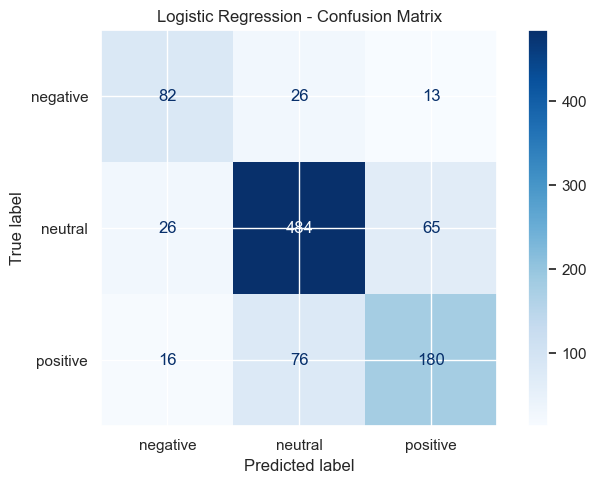

In [25]:
# Display precision, recall, and F1-score for each sentiment class.
print("Logistic Regression Classification Report:\n")

print(
    classification_report(
        y_test,
        lr_predictions,
        labels=sentiment_labels,
        zero_division=0
    )
)

# Calculate the confusion matrix.
lr_cm = confusion_matrix(
    y_test,
    lr_predictions,
    labels=sentiment_labels
)

# Plot the confusion matrix.
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=sentiment_labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

### Logistic Regression Results Discussion

The TF-IDF and Logistic Regression model achieved 77.07% accuracy and a macro F1-score of 0.7275, outperforming the majority-class baseline, VADER, and Naive Bayes.

The model performed best on neutral headlines, with an F1-score of 0.83. Negative and positive headlines had F1-scores of 0.67 and 0.68, respectively.

Compared with Naive Bayes, Logistic Regression made fewer incorrect negative predictions. However, Naive Bayes identified a larger proportion of actual negative headlines.

The results suggest that TF-IDF features with unigrams and bigrams provide a useful representation of financial news sentiment. The model also achieved a cross-validation macro F1-score of 0.7154, which was reasonably close to its test performance.

In [ ]:
# # To install additional packages, use:
# import helpers.hmodule as hmodule
# hmodule.install_module_if_not_present(
#     ["pycaret"],
#     use_activate=True,
#     use_sudo=False,
#     venv_path="/opt/venv",
# )

In [8]:
# Use this for most notebooks.
import helpers.hdbg as hdbg
import helpers.hnotebook as hnotebook

_LOG = logging.getLogger(__name__)

# Initialize notebook configuration and logging.
hdbg.init_logger(verbosity=logging.INFO)
hnotebook.config_notebook()

# Convert `display` into `print()`.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /opt/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py -f /Users/dharshan/Library/Jupyter/runtime/kernel-d22d9d16-6130-4147-9568-b0f00f1c848c.json


## Make the notebook flow clear

Each notebook needs to follow a clear and logical flow, e.g:
- Load data
- Compute stats
- Clean data
- Compute stats
- Do analysis
- Show results

In [ ]:
class Template:
    """
    Brief imperative description of what the class does in one line, if needed.
    """

    def __init__(self) -> None:
        """
        Initialize the Template class.
        """
        pass

    def method1(self, arg1: int) -> None:
        """
        Brief imperative description of what the method does in one line.

        You can elaborate more in the method docstring in this section, for e.g. explaining
        the formula/algorithm. Every method/function should have a docstring, typehints and include the
        parameters and return as follows:

        :param arg1: description of arg1
        :return: description of return
        """
        # Code blocks go here.
        # Make sure to include comments to explain what the code is doing.
        # No empty lines between code blocks.
        pass


def template_function(arg1: int) -> None:
    """
    Brief imperative description of what the function does in one line.

    You can elaborate more in the function docstring in this section, for e.g. explaining
    the formula/algorithm. Every function should have a docstring, typehints and include the
    parameters and return as follows:

    :param arg1: description of arg1
    :return: description of return
    """
    # Code blocks go here.
    # Make sure to include comments to explain what the code is doing.
    # No empty lines between code blocks.
    pass

## The flow should be highlighted using headings in markdown
```
# Level 1
## Level 2
### Level 3
```